# Energy learning: CD, persistent chains, replay and likelihood

A bounded residual over a Gaussian base supplies integrability. Finite negative chains, quadrature resolution and validation selection are different approximations; each has explicit evidence.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
ROOT=Path.cwd()
if ROOT.name == "notebooks": ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
torch.set_num_threads(1)
from sampling_lab.targets import load_target
from sampling_lab.artifacts import sha256
def read(path): return json.loads((ROOT/path).read_text())
def numeric(name): return np.load(ROOT/"assets/source_data"/(name+".npz"),allow_pickle=False)
%matplotlib inline


## Independent implementation check

In [2]:
from sampling_lab.ebm import load,log_partition,langevin
name="ebm_mixture_quadrature_mle_42";folder=ROOT/"results/reference/ebm"/name
model=load(folder/"energy.npz");source=numeric(name);metric=read(str((folder/"metrics.json").relative_to(ROOT)))
with torch.no_grad():
 z=float(log_partition(model,401,18));nll=float((model(torch.from_numpy(source["test"]))+z).mean())
np.testing.assert_allclose(nll,metric["test_nll"],atol=1e-7)
print("Independently normalized test NLL",nll,"partition refinements",metric["partition_refinements"])

Independently normalized test NLL 2.9528422355651855 partition refinements [3.887036455832637, 3.887036485058492, 3.8870373848357813]


## Inspect measured evidence

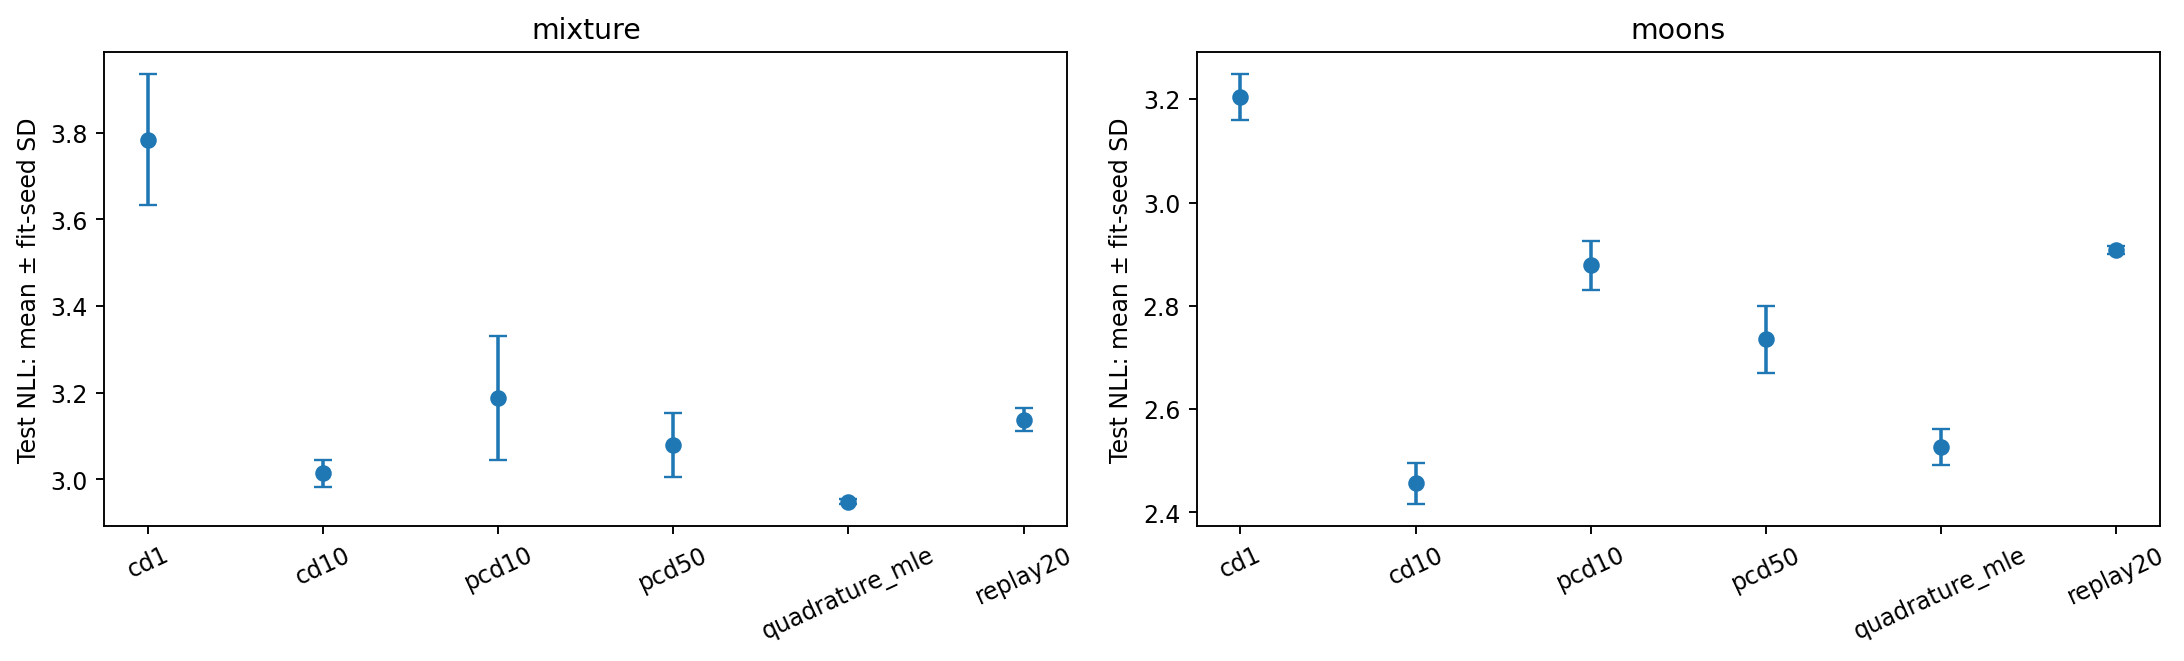

mean       std
task    method                            
mixture cd1             3.783992  0.151315
        cd10            3.014122  0.031186
        pcd10           3.187853  0.143810
        pcd50           3.080158  0.073768
        quadrature_mle  2.948205  0.005542
        replay20        3.137953  0.025804
moons   cd1             3.204046  0.044907
        cd10            2.456359  0.040287
        pcd10           2.878538  0.047867
        pcd50           2.735358  0.065223
        quadrature_mle  2.526714  0.035085
        replay20        2.907783  0.008159

Negative states are detached; gradients do not flow through the chain. Persistent buffers preserve states between optimizer updates.


In [3]:
from IPython.display import Image,display
display(Image(filename=str(ROOT/"assets/figures/energy_objectives.png")))
rows=pd.read_csv(ROOT/"docs/energy_comparison.csv");display(rows.groupby(["task","method"]).test_nll.agg(["mean","std"]))
x=torch.randn(12,2);negative=langevin(model,x,10,.02,torch.Generator().manual_seed(37))
assert not negative.requires_grad and all(p.grad is None for p in model.parameters())
print("Negative states are detached; gradients do not flow through the chain. Persistent buffers preserve states between optimizer updates.")

## Interpretation and next step

Read the [theory](../docs/theory.md), [diagnostic scope](../docs/diagnostics.md), and [data protocol](../docs/data_and_protocols.md). Change one declared preset in a separate output directory; keep warmup, test evaluation and model selection distinct. The [interactive explorer](../docs/explorer.html) exposes the complete recorded comparisons.